# Session 6 · Unsupervised Learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hamnakhan123/Diploma-in-Data-Science/blob/main/term-2/03-advanced-data-science-with-python/code/session-06-unsupervised-learning.ipynb)

Diploma in Data Science · Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run the cells from top to bottom. Every example is self-contained, so you can also run any single cell on its own.

### Example 1 · Basic: K-means from scratch on 2-D data

In [1]:
"""K-means written from scratch with NumPy: assign, update, repeat, and track inertia."""
import numpy as np

rng = np.random.default_rng(0)
# Three neighbourhoods of delivery addresses (km east, km north)
X = np.vstack([rng.normal([2, 2], .6, (50, 2)), rng.normal([8, 3], .8, (50, 2)), rng.normal([5, 8], .7, (50, 2))])

def kmeans(X, k, iters=20, seed=1):
    r = np.random.default_rng(seed)
    centres = X[r.choice(len(X), k, replace=False)]           # random initial centres
    for it in range(iters):
        d = np.linalg.norm(X[:, None, :] - centres[None, :, :], axis=2)   # distance to each centre
        labels = d.argmin(axis=1)                                         # assign
        new = np.array([X[labels == j].mean(axis=0) for j in range(k)])   # update
        inertia = ((X - new[labels]) ** 2).sum()
        print(f"iteration {it + 1}: inertia = {inertia:8.2f}")
        if np.allclose(new, centres):
            break
        centres = new
    return labels, centres

labels, centres = kmeans(X, 3)
print("\nfinal centres (km):\n", centres.round(2))
print("points per cluster:", np.bincount(labels))

iteration 1: inertia =   520.38
iteration 2: inertia =   149.83
iteration 3: inertia =   149.83

final centres (km):
 [[1.99 2.11]
 [7.9  3.02]
 [4.75 8.05]]
points per cluster: [50 50 50]


### Example 2 · Intermediate: choosing k with elbow and silhouette

k=2: inertia=  494.4  silhouette=0.586
k=3: inertia=  135.9  silhouette=0.755
k=4: inertia=   37.4  silhouette=0.782
k=5: inertia=   33.6  silhouette=0.667
k=6: inertia=   30.0  silhouette=0.542
k=7: inertia=   26.4  silhouette=0.478
k=8: inertia=   22.8  silhouette=0.354


k=9: inertia=   20.6  silhouette=0.364
best k by silhouette: 4


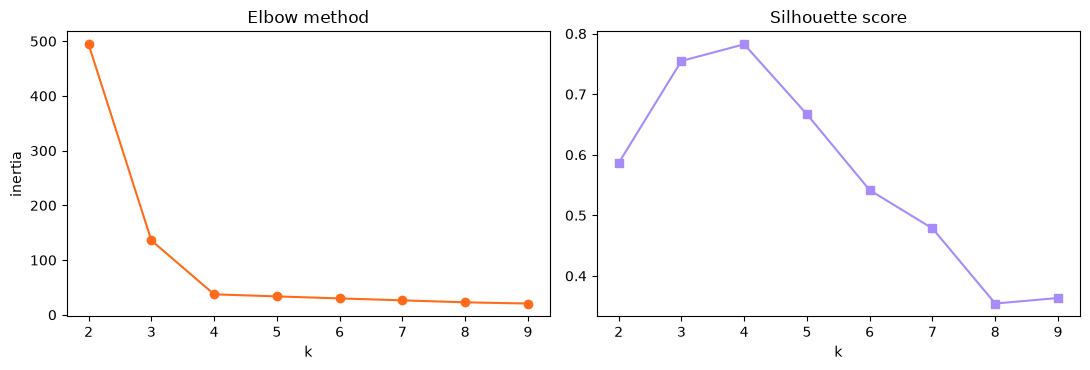

In [2]:
"""Elbow (inertia) and silhouette analysis to choose k for K-means; saves a two-panel chart."""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

X, _ = make_blobs(n_samples=600, centers=4, cluster_std=1.1, random_state=7)
X = StandardScaler().fit_transform(X)
ks = range(2, 10)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    inertia.append(km.inertia_); sil.append(silhouette_score(X, km.labels_))
    print(f"k={k}: inertia={km.inertia_:7.1f}  silhouette={sil[-1]:.3f}")
print("best k by silhouette:", list(ks)[int(np.argmax(sil))])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(list(ks), inertia, "o-", color="#FF6B1A"); ax[0].set_title("Elbow method"); ax[0].set_xlabel("k"); ax[0].set_ylabel("inertia")
ax[1].plot(list(ks), sil, "s-", color="#A78BFA"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
fig.tight_layout(); fig.savefig("session-06_choose_k.png", dpi=110); plt.show()

### Example 3 · Intermediate: four clustering families on tricky shapes

algorithm                moons ARI blobs ARI
K-means                       0.47      0.84
Agglomerative (single)        1.00      0.00
DBSCAN                        1.00      0.55
Gaussian mixture              0.50      0.94


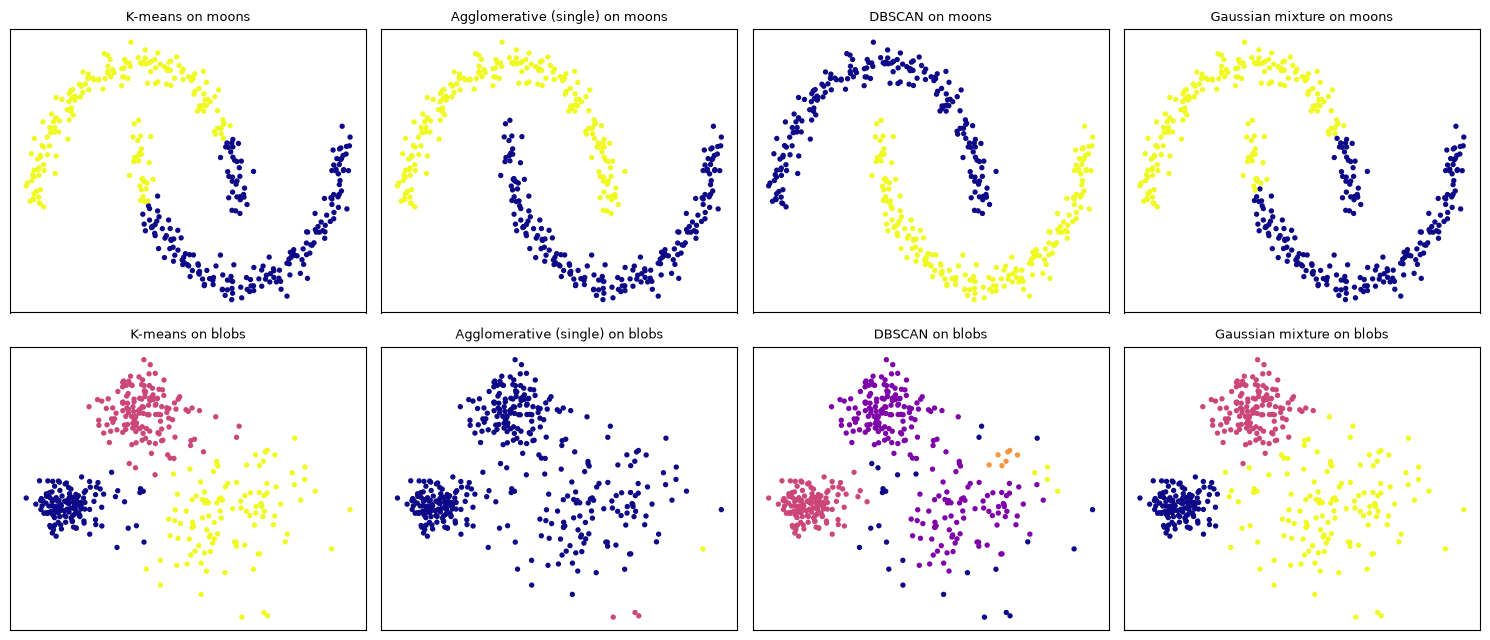

In [3]:
"""K-means, agglomerative, DBSCAN and Gaussian mixture on moons and blobs: who copes with which shape?"""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

moons, ym = make_moons(400, noise=.06, random_state=0)
blobs, yb = make_blobs(400, centers=[[0, 0], [4, 0], [2, 3]], cluster_std=[.4, 1.2, .6], random_state=0)
datasets = {"moons": (StandardScaler().fit_transform(moons), ym), "blobs": (StandardScaler().fit_transform(blobs), yb)}
algos = {
    "K-means": lambda k: KMeans(k, n_init=10, random_state=0),
    "Agglomerative (single)": lambda k: AgglomerativeClustering(k, linkage="single"),
    "DBSCAN": lambda k: DBSCAN(eps=0.3, min_samples=5),
    "Gaussian mixture": lambda k: GaussianMixture(k, random_state=0),
}
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
print(f"{'algorithm':<24}{'moons ARI':>10}{'blobs ARI':>10}")
scores = {a: [] for a in algos}
for r, (dname, (X, y)) in enumerate(datasets.items()):
    k = len(set(y))
    for c, (aname, make) in enumerate(algos.items()):
        labels = make(k).fit_predict(X)
        scores[aname].append(adjusted_rand_score(y, labels))
        axes[r, c].scatter(X[:, 0], X[:, 1], c=labels, cmap="plasma", s=8)
        axes[r, c].set_title(f"{aname} on {dname}", fontsize=9); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
for a, s in scores.items():
    print(f"{a:<24}{s[0]:>10.2f}{s[1]:>10.2f}")
fig.tight_layout(); fig.savefig("session-06_cluster_families.png", dpi=100); plt.show()

### Example 4 · Intermediate: PCA and association rules in a few lines

In [4]:
"""PCA on the 64-pixel digits data, then Apriori association rules with mlxtend."""
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

X, y = load_digits(return_X_y=True)                    # 1797 images, 8x8 = 64 features
pca = PCA().fit(X)
cum = pca.explained_variance_ratio_.cumsum()
for n in [2, 10, 20, 30]:
    print(f"{n:>2} components keep {cum[n - 1]:.1%} of the variance")
print("components needed for 90%:", int((cum < .90).sum()) + 1, "of 64")

baskets = [["tea", "sugar", "rusk"], ["tea", "sugar"], ["tea", "milk", "rusk"], ["bread", "eggs", "milk"],
           ["bread", "eggs"], ["tea", "sugar", "milk"], ["bread", "milk", "eggs", "tea"], ["tea", "rusk"],
           ["sugar", "tea", "rusk"], ["eggs", "bread", "butter"]]
te = TransactionEncoder()
onehot = pd.DataFrame(te.fit(baskets).transform(baskets), columns=te.columns_)
freq = apriori(onehot, min_support=0.3, use_colnames=True)
rules = association_rules(freq, metric="lift", min_threshold=1.2)
rules["rule"] = rules["antecedents"].apply(lambda s: ", ".join(sorted(s))) + " -> " + rules["consequents"].apply(lambda s: ", ".join(sorted(s)))
print("\n", rules[["rule", "support", "confidence", "lift"]].round(2).sort_values("lift", ascending=False).to_string(index=False))

 2 components keep 28.5% of the variance
10 components keep 73.8% of the variance
20 components keep 89.4% of the variance
30 components keep 95.9% of the variance
components needed for 90%: 21 of 64

          rule  support  confidence  lift
eggs -> bread      0.4        1.00  2.50
bread -> eggs      0.4        1.00  2.50
  rusk -> tea      0.4        1.00  1.43
  tea -> rusk      0.4        0.57  1.43
 tea -> sugar      0.4        0.57  1.43
 sugar -> tea      0.4        1.00  1.43


### Example 5 · Advanced: anomaly detection, five ways

In [5]:
"""Detect injected anomalies in sensor data with z-score, IQR, Isolation Forest, LOF and One-Class SVM."""
import numpy as np
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score

rng = np.random.default_rng(3)
# Factory motor: temperature (°C) and vibration (mm/s) are correlated in normal operation
temp = rng.normal(70, 4, 980)
vib = 2 + 0.05 * (temp - 70) + rng.normal(0, .15, 980)
normal = np.c_[temp, vib]
# 20 anomalies: normal temperature but unusual vibration for that temperature (a bearing fault)
t_bad = rng.normal(70, 4, 20)
bad = np.c_[t_bad, 2 + 0.05 * (t_bad - 70) + rng.choice([-1, 1], 20) * rng.uniform(.6, 1.0, 20)]
X = np.vstack([normal, bad]); y = np.r_[np.zeros(980), np.ones(20)].astype(int)
Xs = StandardScaler().fit_transform(X)

def report(name, flags):
    print(f"{name:<22} flagged {flags.sum():>3}  precision {precision_score(y, flags):.2f}  recall {recall_score(y, flags):.2f}")

z = np.abs(Xs).max(axis=1); report("z-score > 3 (per col)", (z > 3).astype(int))
q1, q3 = np.percentile(X, [25, 75], axis=0); iqr = q3 - q1
report("IQR rule (per col)", ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).any(axis=1).astype(int))
report("Isolation Forest", (IsolationForest(contamination=.02, random_state=0).fit_predict(Xs) == -1).astype(int))
report("Local Outlier Factor", (LocalOutlierFactor(n_neighbors=30, contamination=.02).fit_predict(Xs) == -1).astype(int))
report("One-Class SVM", (OneClassSVM(nu=.02, gamma=.5).fit(Xs).predict(Xs) == -1).astype(int))

z-score > 3 (per col)  flagged  15  precision 0.73  recall 0.55
IQR rule (per col)     flagged  22  precision 0.55  recall 0.60


Isolation Forest       flagged  20  precision 0.40  recall 0.40
Local Outlier Factor   flagged  20  precision 1.00  recall 1.00
One-Class SVM          flagged  43  precision 0.23  recall 0.50


### 🏙️ Real-life data problem: segmenting supermarket customers

k=2: silhouette = 0.569
k=3: silhouette = 0.561


k=4: silhouette = 0.585


k=5: silhouette = 0.487


k=6: silhouette = 0.455


k=7: silhouette = 0.377

Segment profiles (medians):
          recency_days  frequency  avg_basket  monetary  customers                    name
segment                                                                                  
3                14.0       37.0      9064.0  330444.0        207  Champions (high value)
2                10.0       60.0      1783.0  109964.0        599          Loyal regulars
0                35.0       13.0      4480.0   56895.0        494        Monthly stock-up
1               101.0        5.0       912.0    4398.0        700    Occasional / at risk



accounts flagged for review: 6
      recency_days  frequency  avg_basket   monetary  spend_gap
220            7.0         43      1543.0   995235.0        2.7
315           11.0         81      1118.0  1358370.0        2.7
393            5.0         64      2384.0  2288640.0        2.7
519           20.0         56      3028.0  2543520.0        2.7
548            9.0         58      1215.0  1057050.0        2.7
1381          99.0          1       604.0      604.0        0.0


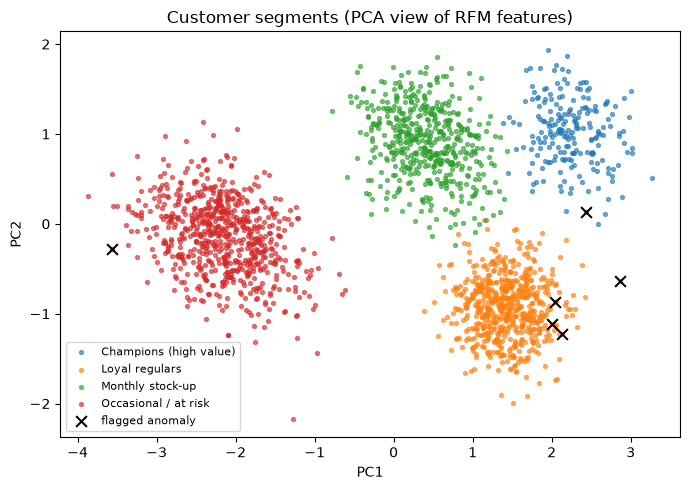

In [6]:
"""Real-life problem: RFM customer segmentation with K-means, profiling, PCA view and anomaly flags."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest

rng = np.random.default_rng(12)
groups = [  # (count, recency days, visits/year, avg basket Rs)
    (600, 10, 60, 1800),    # loyal regulars
    (500, 40, 12, 4500),    # monthly big-basket shoppers
    (700, 120, 4, 900),     # occasional
    (200, 15, 35, 9000),    # high-value families
]
rows = []
for n, r, f, m in groups:
    rows.append(pd.DataFrame({"recency_days": rng.gamma(2, r / 2, n).round() + 1,
                              "frequency": rng.poisson(f, n) + 1,
                              "avg_basket": rng.lognormal(np.log(m), .25, n).round()}))
cust = pd.concat(rows, ignore_index=True)
cust["monetary"] = cust["frequency"] * cust["avg_basket"]
cust.loc[rng.choice(len(cust), 6, replace=False), "monetary"] *= 15     # a few suspicious accounts

features = ["recency_days", "frequency", "avg_basket", "monetary"]
X = StandardScaler().fit_transform(np.log1p(cust[features]))           # log first: RFM is very skewed
for k in range(2, 8):
    lab = KMeans(k, n_init=10, random_state=0).fit_predict(X)
    print(f"k={k}: silhouette = {silhouette_score(X, lab):.3f}")
km = KMeans(4, n_init=10, random_state=0).fit(X)
cust["segment"] = km.labels_

profile = cust.groupby("segment")[features].median().round(0)
profile["customers"] = cust["segment"].value_counts().sort_index()
profile = profile.sort_values("monetary", ascending=False)
names = ["Champions (high value)", "Loyal regulars", "Monthly stock-up", "Occasional / at risk"]
profile["name"] = names
print("\nSegment profiles (medians):\n", profile.to_string())

# Consistency check: total spend should equal visits x average basket; a big gap is suspicious
cust["spend_gap"] = np.log(cust["monetary"] / (cust["frequency"] * cust["avg_basket"]))
X_anom = np.c_[X, StandardScaler().fit_transform(cust[["spend_gap"]])]
cust["anomaly"] = IsolationForest(contamination=0.003, random_state=0).fit_predict(X_anom) == -1
print(f"\naccounts flagged for review: {cust['anomaly'].sum()}")
print(cust[cust["anomaly"]][features + ["spend_gap"]].round(1).to_string())

name_of = dict(zip(profile.index, names))
P = PCA(2).fit_transform(X)
plt.figure(figsize=(7, 5))
for s in profile.index:
    m = cust["segment"] == s
    plt.scatter(P[m, 0], P[m, 1], s=8, alpha=.6, label=name_of[s])
plt.scatter(P[cust.anomaly, 0], P[cust.anomaly, 1], marker="x", s=60, color="black", label="flagged anomaly")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Customer segments (PCA view of RFM features)"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig("session-06_customer_segments.png", dpi=110); plt.show()

### 🧩 Mini project: unsupervised toolkit report for a city's air-quality sensors

In [7]:
"""Mini project: cluster air-quality stations, reduce dimensions with PCA and flag faulty readings."""
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest

rng = np.random.default_rng(4)
profiles = {"industrial": [180, 90, 60, 45], "traffic": [140, 110, 35, 30], "residential": [80, 45, 20, 15], "coastal": [55, 25, 12, 10]}
rows = []
for zone, (pm25, no2, so2, co) in profiles.items():
    for s in range(12):
        for day in range(30):
            rows.append([f"{zone[:3].upper()}-{s:02d}", zone, *(np.array([pm25, no2, so2, co]) * rng.lognormal(0, .15, 4))])
df = pd.DataFrame(rows, columns=["station", "zone", "pm25", "no2", "so2", "co"])
df.loc[rng.choice(len(df), 15, replace=False), ["pm25", "co"]] = [[900, 2]]      # sensor glitches

pollutants = ["pm25", "no2", "so2", "co"]
X = StandardScaler().fit_transform(np.log(df[pollutants]))
df["faulty"] = IsolationForest(contamination=0.01, random_state=0).fit_predict(X) == -1
print("readings flagged as faulty:", int(df.faulty.sum()))

stations = df[~df.faulty].groupby("station")[pollutants].mean()
S = StandardScaler().fit_transform(np.log(stations))
best_k = max(range(2, 7), key=lambda k: silhouette_score(S, KMeans(k, n_init=10, random_state=0).fit_predict(S)))
stations["cluster"] = KMeans(best_k, n_init=10, random_state=0).fit_predict(S)
print("best number of station groups:", best_k)
print(stations.groupby("cluster")[pollutants].mean().round(1).assign(stations=stations.cluster.value_counts().sort_index()).to_string())

pca = PCA(2).fit(S)
print("\nPCA: 2 components explain", f"{pca.explained_variance_ratio_.sum():.1%}", "of station-level variation")
print("PC1 loadings:", {p: round(float(v), 2) for p, v in zip(pollutants, pca.components_[0])})

readings flagged as faulty: 15
best number of station groups: 4
          pm25    no2   so2    co  stations
cluster                                    
0         82.2   45.5  20.4  15.0        12
1        142.5  110.8  35.3  30.4        12
2         55.9   25.4  12.3  10.1        12
3        182.0   91.2  60.4  45.7        12

PCA: 2 components explain 99.8% of station-level variation
PC1 loadings: {'pm25': 0.51, 'no2': 0.49, 'so2': 0.5, 'co': 0.5}
